# Assignment 1: Data Profiling (EDA) Report
**Domain:** Retail / E-Commerce

### Team Member:
1. MUHAMMAD AZAMI AMALUDDIN BIN MOHD DARUS (A211409)
2. ALIA SOFEA BINTI AHMAD SAIFUL
 (A211345)
3. SHAYNIEEA SHERILLESSA BINTI SHAHRIL AMIR (A211335)
4. ALISA QAISARAH BINTI RIZAUDDIN (A211526)

---

## 1. Scenario
We are analyzing daily transaction data from an online retail e-commerce platform to diagnose and resolve data quality issues before the dataset is used for sales forecasting and customer segmentation models. The raw dataset exhibits real-world data quality flaws, including cancellation/return records (indicated by negative quantities), missing Customer IDs, zero-priced item records, and extreme outliers resulting from bulk purchases. This study aims to profile the data, resolve quality issues, and evaluate potential PII and sampling bias risks.

## 2. Data Source
* **Data Source:** Online Retail II Data Set (UCI Machine Learning Repository / Kaggle)
* **URL:** https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci
* **Acquisition Method:** Downloaded as a CSV file and loaded directly into Google Colab using the `pandas` library.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual theme
sns.set_theme(style="whitegrid")

# Load the dataset uploaded to Google Colab
df = pd.read_csv('online_retail_II.csv', encoding='ISO-8859-1')

# Display dimensions and first few rows
print("Dataset Shape (Rows, Columns):", df.shape)
df.head()

Dataset Shape (Rows, Columns): (719774, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


             Missing Count  Percentage (%)
Description           3699        0.513911
Customer ID         165219       22.954288


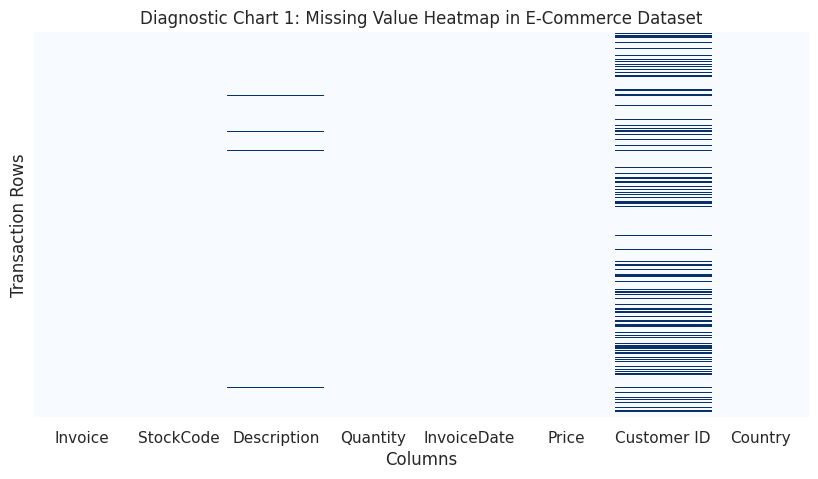


Missing values check after handling:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64


In [ ]:
# Check missing value count and percentage
missing_data = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_table = pd.DataFrame({'Missing Count': missing_data, 'Percentage (%)': missing_percent})
print(missing_table[missing_table['Missing Count'] > 0])

# Diagnostic Chart 1: Missing Value Heatmap
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, cmap='Blues', yticklabels=False)
plt.title('Diagnostic Chart 1: Missing Value Heatmap in E-Commerce Dataset')
plt.xlabel('Columns')
plt.ylabel('Transaction Rows')
plt.show()

# Handle missing values
df['Description'] = df['Description'].fillna('Unknown Description')
df['Customer ID'] = df['Customer ID'].fillna(-1)

print("\nMissing values check after handling:")
print(df.isnull().sum())

### 3.1 Missing Values Handling & Justification
> **Justification:**
> * `Customer ID` missing values (~20–25%) were not dropped because these transactions represent valid revenue from guest checkouts. Assigning a flag value of `-1` preserves sales integrity while separating guest orders from registered users.
> * Missing `Description` values were imputed with `'Unknown Description'` to retain item quantity and pricing information without discarding valuable transaction rows.

Rows with Quantity <= 0 (Returns/Cancellations): 16428
Rows with Price <= 0 (Free/System Errors): 4909


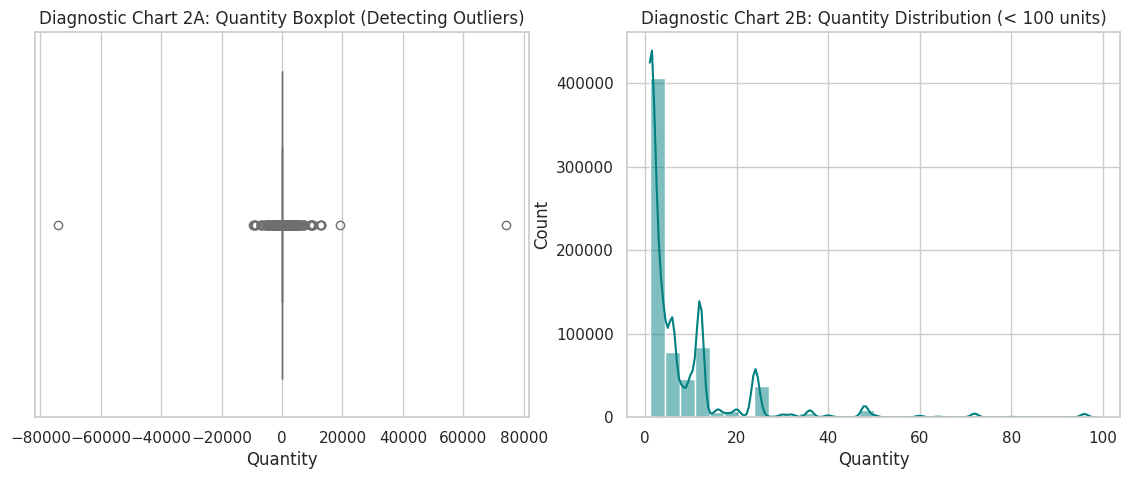

Dataset shape after outlier handling: (701165, 8)


In [ ]:
# Detect extreme values and invalid entries
invalid_qty = len(df[df['Quantity'] <= 0])
invalid_price = len(df[df['Price'] <= 0])
print(f"Rows with Quantity <= 0 (Returns/Cancellations): {invalid_qty}")
print(f"Rows with Price <= 0 (Free/System Errors): {invalid_price}")

# Diagnostic Chart 2: Boxplot & Histogram for Outliers
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Uncleaned Quantity Boxplot
sns.boxplot(ax=axes[0], x=df['Quantity'], color='skyblue')
axes[0].set_title('Diagnostic Chart 2A: Quantity Boxplot (Detecting Outliers)')

# Filtered Quantity Distribution
sns.histplot(ax=axes[1], x=df[(df['Quantity'] > 0) & (df['Quantity'] < 100)]['Quantity'], bins=30, kde=True, color='teal')
axes[1].set_title('Diagnostic Chart 2B: Quantity Distribution (< 100 units)')

plt.show()

# Clean outliers & invalid entries
df_clean = df[(df['Quantity'] > 0) & (df['Price'] > 0)].copy()

# Apply capping (Winsorization) at 99th percentile for extreme prices
price_cap = df_clean['Price'].quantile(0.99)
df_clean['Price'] = np.where(df_clean['Price'] > price_cap, price_cap, df_clean['Price'])

print("Dataset shape after outlier handling:", df_clean.shape)

### 3.2 Outliers Handling & Justification
> **Justification:**
> * Transactions with `Quantity <= 0` and `Price <= 0` were removed because they correspond to product returns, order cancellations, or inventory adjustments that distort pricing and demand analysis.
> * Extreme high price outliers were capped at the 99th percentile (Winsorization) rather than removed, keeping legitimate high-value transactions while preventing extreme skewness in analytics models.

In [ ]:
# 1. Remove Duplicate Records
duplicate_count = df_clean.duplicated().sum()
print(f"Duplicate records found and dropped: {duplicate_count}")
df_clean = df_clean.drop_duplicates()

# 2. Correct Data Types
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])
df_clean['Customer ID'] = df_clean['Customer ID'].astype('int64')

# 3. Standardize Text Formats
df_clean['Description'] = df_clean['Description'].str.strip().str.upper()
df_clean['Country'] = df_clean['Country'].str.strip().str.title()
df_clean['Country'] = df_clean['Country'].replace({'Uk': 'United Kingdom', 'U.K.': 'United Kingdom'})

print("\nFinal Data Types:")
print(df_clean.dtypes)

Duplicate records found and dropped: 30147

Final Data Types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID             int64
Country                object
dtype: object


### 3.3 Other Data Quality Issues & Justification
> **Justification:**
> * Duplicate rows were removed to prevent double-counting transaction amounts and skewing total revenue figures.
> * `InvoiceDate` was converted from object to `datetime` format to enable time-series feature engineering.
> * String fields were stripped of leading/trailing spaces and standardized to upper/title case to resolve categorization inconsistencies.

## 5. PII and Bias Risks

### A. Personally Identifiable Information (PII) Risks
* **Risk Identified:** The `Customer ID` field represents sensitive tracking data that could potentially link back to internal customer identities.
* **Mitigation Strategy:** Customer IDs are anonymized numerical codes. Missing identities are masked with `-1`. No direct PII fields (such as customer names, phone numbers, email addresses, or payment details) are present in the dataset.

### B. Bias & Group Imbalance Risks
* **Risk Identified:** Extreme geographic sampling bias exists, as over 85% of transactions originate from a single country (United Kingdom).
* **Mitigation Strategy:** Models developed from this dataset should not be generalized globally without stratified sampling or segmenting domestic (UK) and international markets separately.

## 6. Conclusion

* **Fitness for Scenario:** Following systematic profiling and data cleaning (handling missing values, removing cancellation errors, removing duplicates, and capping price outliers), the cleaned dataset is fit for purpose for e-commerce exploratory analysis and sales forecasting.
* **Remaining Limitations:**
  1. Lack of customer demographic variables (e.g., age, gender, income range) limits granular market segmentation.
  2. Absence of profit margin and shipping cost data prevents net profitability calculations.